In [6]:
# CELL 1 - Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy.stats import ttest_ind, fisher_exact
from scipy.stats import false_discovery_control

import scipy
print(f"SciPy version: {scipy.__version__}")

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({"figure.dpi": 120, "figure.figsize": (10, 5)})

print("Libraries loaded successfully")

SciPy version: 1.17.1
Libraries loaded successfully


In [7]:
# CELL 2 - Load dataset
df = pd.read_csv("lab_statistical_analysis/marketing_data_raw.csv")

print("=== SHAPE ===")
print(df.shape)

print("\n=== COLUMNS AND TYPES ===")
print(df.dtypes)

print("\n=== FIRST ROWS ===")
df.head(3)

=== SHAPE ===
(200000, 16)

=== COLUMNS AND TYPES ===
Campaign_ID           int64
Company                 str
Campaign_Type           str
Target_Audience         str
Duration                str
Channel_Used            str
Conversion_Rate     float64
Acquisition_Cost        str
ROI                 float64
Location                str
Language                str
Clicks                int64
Impressions           int64
Engagement_Score      int64
Customer_Segment        str
Date                    str
dtype: object

=== FIRST ROWS ===


,Campaign_ID,Company,Campaign_Type,Target_Audience,Duration,Channel_Used,Conversion_Rate,Acquisition_Cost,ROI,Location,Language,Clicks,Impressions,Engagement_Score,Customer_Segment,Date
0,1,Innovate Industries,Email,Men 18-24,30 days,Google Ads,0.04,"$16,174.00",6.29,Chicago,Spanish,506,1922,6,Health & Wellness,2021-01-01
1,2,NexGen Systems,Email,Women 35-44,60 days,Google Ads,0.12,"$11,566.00",5.61,New York,German,116,7523,7,Fashionistas,2021-01-02
2,3,Alpha Innovations,Influencer,Men 25-34,30 days,YouTube,0.07,"$10,200.00",7.18,Los Angeles,French,584,7698,1,Outdoor Adventurers,2021-01-03


In [8]:
# CELL 3 - Data quality check
print("=== NULL VALUES ===")
print(df.isnull().sum())

print("\n=== DESCRIPTIVE STATISTICS ===")
df.describe().round(2)

=== NULL VALUES ===
Campaign_ID         0
Company             0
Campaign_Type       0
Target_Audience     0
Duration            0
Channel_Used        0
Conversion_Rate     0
Acquisition_Cost    0
ROI                 0
Location            0
Language            0
Clicks              0
Impressions         0
Engagement_Score    0
Customer_Segment    0
Date                0
dtype: int64

=== DESCRIPTIVE STATISTICS ===


,Campaign_ID,Conversion_Rate,ROI,Clicks,Impressions,Engagement_Score
count,200000.00,200000.00,200000.00,200000.00,200000.00,200000.00
mean,100000.50,0.08,5.00,549.77,5507.30,5.49
std,57735.17,0.04,1.73,260.02,2596.86,2.87
min,1.00,0.01,2.00,100.00,1000.00,1.00
25%,50000.75,0.05,3.50,325.00,3266.00,3.00
50%,100000.50,0.08,5.01,550.00,5517.50,5.00
75%,150000.25,0.12,6.51,775.00,7753.00,8.00
max,200000.00,0.15,8.00,1000.00,10000.00,10.00


In [9]:
# CELL 4 - Data cleaning and preparation
df["Acquisition_Cost"] = (
    df["Acquisition_Cost"]
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False)
    .astype(float)
)

df["Revenue"] = df["Acquisition_Cost"] * (1 + df["ROI"])

grouping_col = "Channel_Used"
print("=== AVAILABLE CHANNELS ===")
print(df[grouping_col].value_counts())
print(f"\nTotal channels: {df[grouping_col].nunique()}")

print("\n=== Acquisition_Cost sample ===")
print(df["Acquisition_Cost"].head())

=== AVAILABLE CHANNELS ===
Channel_Used
Email         33599
Google Ads    33438
YouTube       33392
Instagram     33392
Website       33360
Facebook      32819
Name: count, dtype: int64

Total channels: 6

=== Acquisition_Cost sample ===
0    16174.0
1    11566.0
2    10200.0
3    12724.0
4    16452.0
Name: Acquisition_Cost, dtype: float64


In [10]:
# CELL 5 - Aggregated metrics by channel
agg = df.groupby(grouping_col).agg(
    Impressions = ("Impressions",      "sum"),
    Clicks      = ("Clicks",           "sum"),
    Conversions = ("Conversion_Rate",  "sum"),
    Cost        = ("Acquisition_Cost", "sum"),
    Revenue     = ("Revenue",          "sum"),
).reset_index()

agg["CTR"]           = agg["Clicks"]      / agg["Impressions"]
agg["Conv_Rate"]     = agg["Conversions"] / agg["Clicks"]
agg["CPA"]           = agg["Cost"]        / agg["Conversions"]
agg["ROAS"]          = agg["Revenue"]     / agg["Cost"]
agg["Profit"]        = agg["Revenue"]     - agg["Cost"]
agg["Profit_Margin"] = agg["Profit"]      / agg["Revenue"]

agg.replace([np.inf, -np.inf], np.nan, inplace=True)

print("=== CHANNEL SUMMARY ===")
display(agg.round(2))

=== CHANNEL SUMMARY ===


,Channel_Used,Impressions,Clicks,Conversions,Cost,Revenue,CTR,Conv_Rate,CPA,ROAS,Profit,Profit_Margin
0,Email,184801107,18493963,2697.38,420874104.0,2.524644e+09,0.1,0.0,156030.71,6.00,2.103770e+09,0.83
1,Facebook,180659428,18037947,2625.25,410595258.0,2.474541e+09,0.1,0.0,156402.35,6.03,2.063945e+09,0.83
2,Google Ads,185006879,18340807,2681.17,418912314.0,2.516724e+09,0.1,0.0,156242.35,6.01,2.097811e+09,0.83
3,Instagram,183738455,18316654,2667.57,417124850.0,2.497101e+09,0.1,0.0,156368.85,5.99,2.079977e+09,0.83
4,Website,183806353,18414628,2674.90,416593500.0,2.504152e+09,0.1,0.0,155741.71,6.01,2.087559e+09,0.83
5,YouTube,183448082,18350407,2667.66,416778582.0,2.501105e+09,0.1,0.0,156233.77,6.00,2.084326e+09,0.83


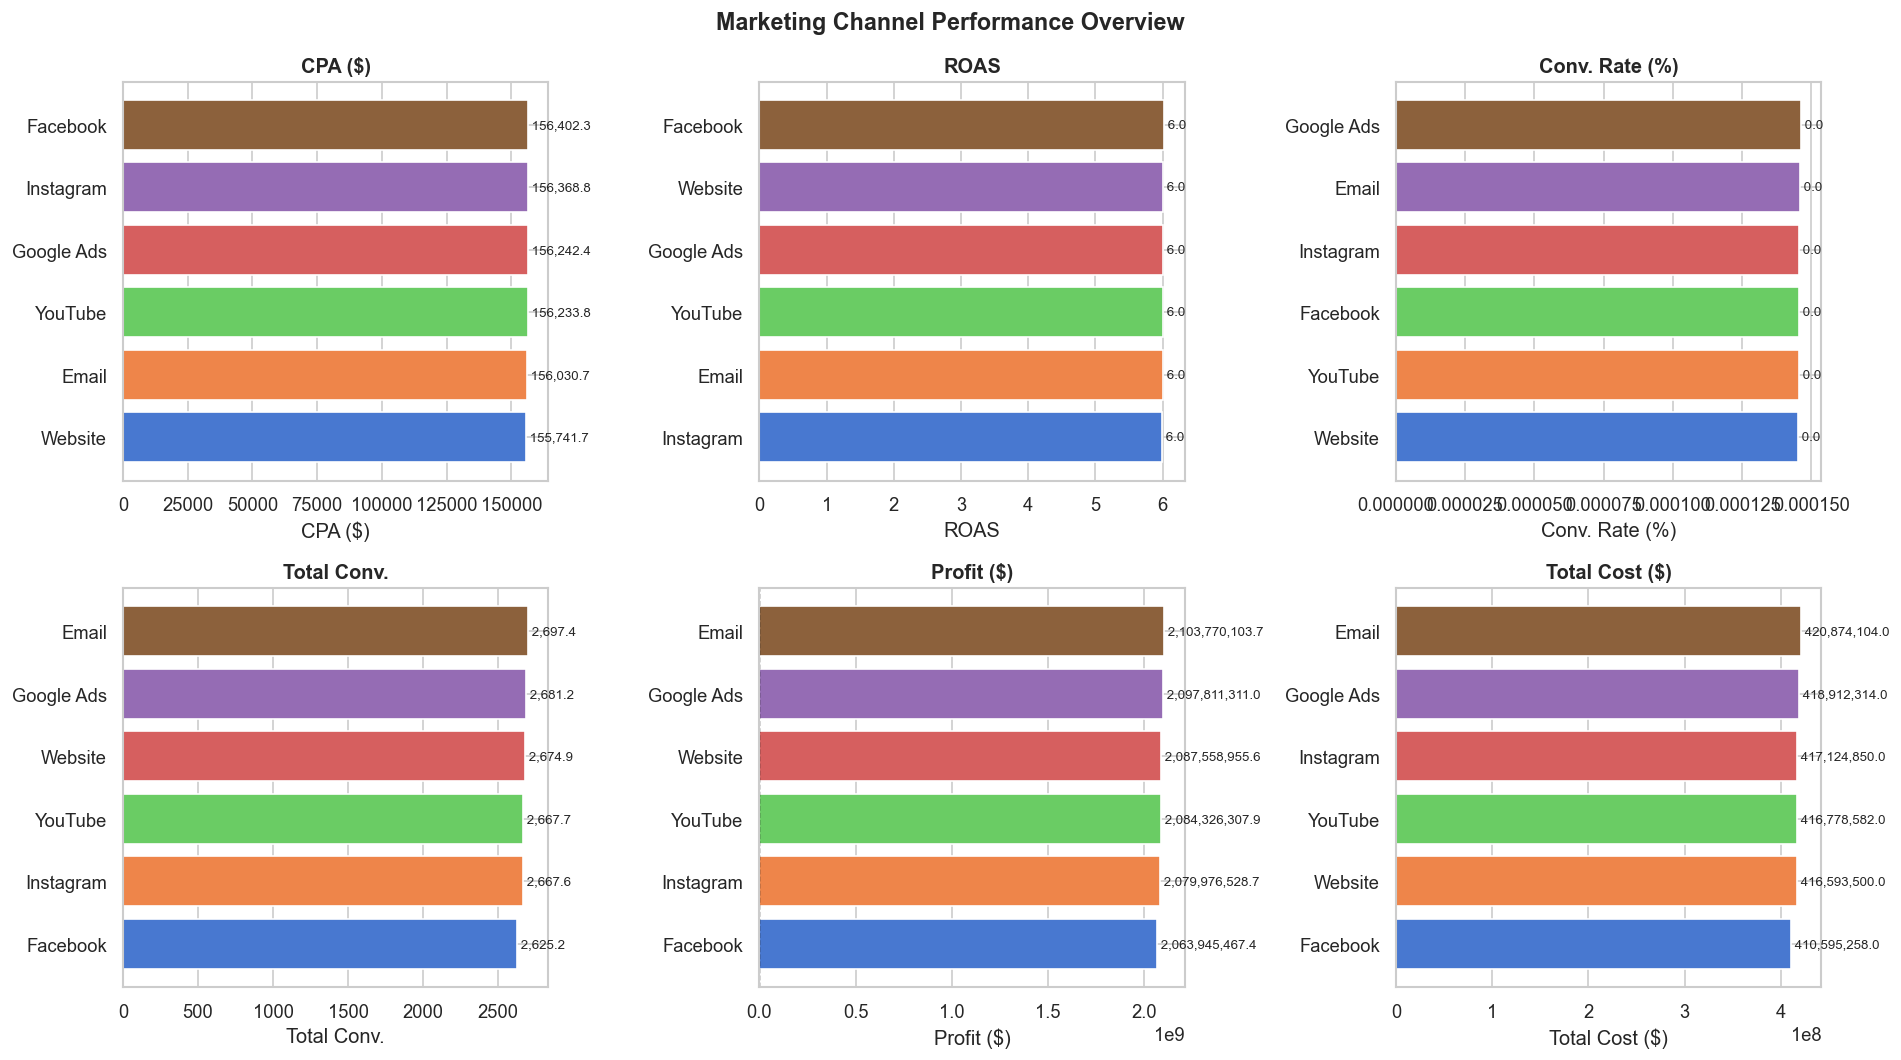

Saved: group_metrics_overview.png


In [11]:
# CELL 6 - Key metrics visualization
metrics = {
    "CPA ($)"          : ("CPA",         False),
    "ROAS"             : ("ROAS",        True),
    "Conv. Rate (%)"   : ("Conv_Rate",   True),
    "Total Conv."      : ("Conversions", True),
    "Profit ($)"       : ("Profit",      True),
    "Total Cost ($)"   : ("Cost",        False),
}

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()
palette = sns.color_palette("muted", n_colors=len(agg))

for ax, (label, (col, higher_is_better)) in zip(axes, metrics.items()):
    data = agg[[grouping_col, col]].dropna().sort_values(col, ascending=True)
    bars = ax.barh(data[grouping_col], data[col], color=palette)
    ax.set_title(label, fontweight="bold")
    ax.set_xlabel(label)
    if col == "Profit":
        ax.axvline(0, color="black", linewidth=0.8, linestyle="--")
    for bar in bars:
        w = bar.get_width()
        ax.text(w, bar.get_y() + bar.get_height() / 2,
                f" {w:,.1f}", va="center", fontsize=8)

plt.suptitle("Marketing Channel Performance Overview", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("group_metrics_overview.png", bbox_inches="tight")
plt.show()
print("Saved: group_metrics_overview.png")

/var/folders/j4/tj_8y31166z4t719q6hvtnmw0000gn/T/ipykernel_62797/2606785650.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=grouping_col, y=col, ax=ax, palette="muted")
/var/folders/j4/tj_8y31166z4t719q6hvtnmw0000gn/T/ipykernel_62797/2606785650.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=grouping_col, y=col, ax=ax, palette="muted")
/var/folders/j4/tj_8y31166z4t719q6hvtnmw0000gn/T/ipykernel_62797/2606785650.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=grouping_col, y=col, ax=ax, palette="

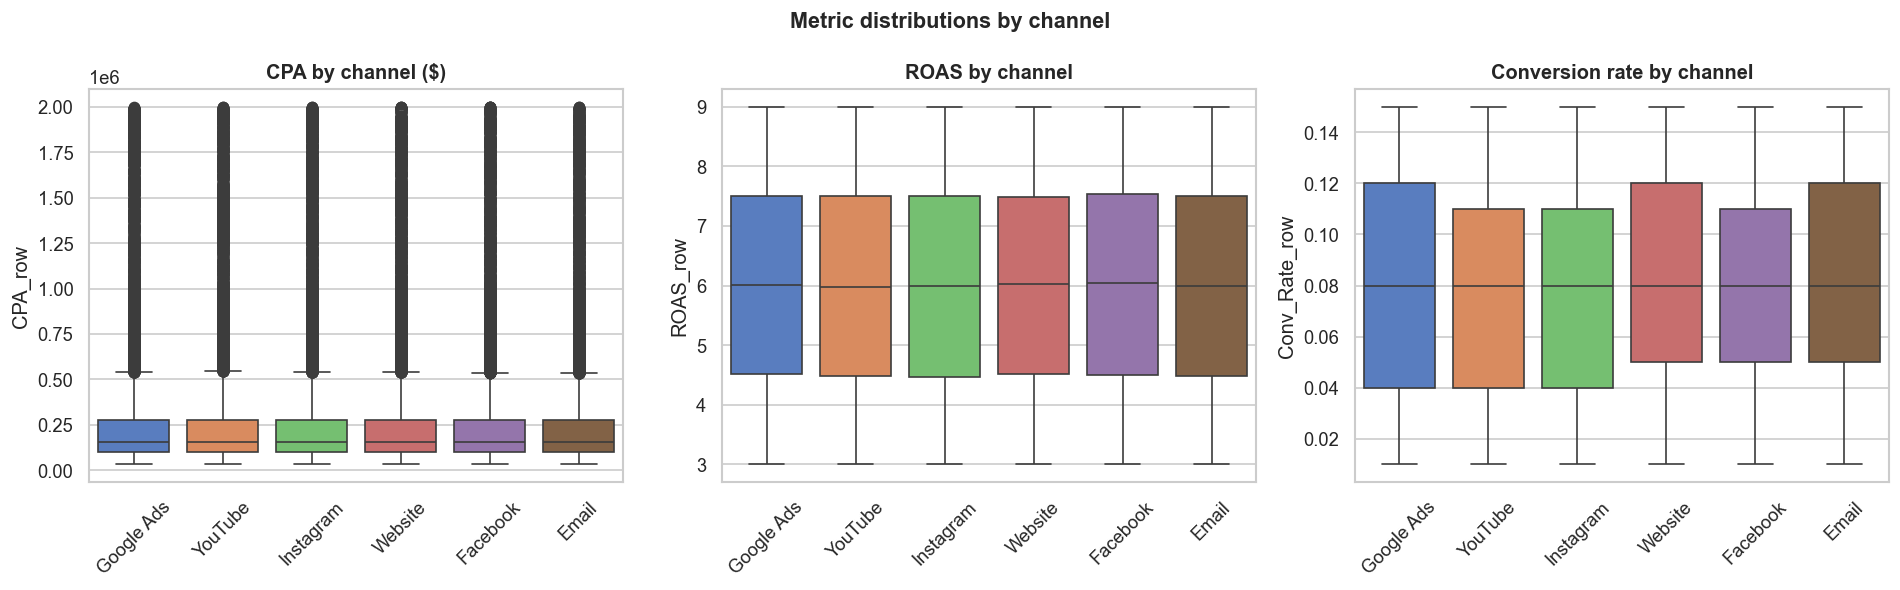

Saved: group_distributions.png


In [12]:
# CELL 7 - Distribution plots
df["CPA_row"]       = df["Acquisition_Cost"] / df["Conversion_Rate"].replace(0, np.nan)
df["ROAS_row"]      = df["Revenue"]          / df["Acquisition_Cost"].replace(0, np.nan)
df["Conv_Rate_row"] = df["Conversion_Rate"]

df.replace([np.inf, -np.inf], np.nan, inplace=True)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (col, title) in zip(axes, [
    ("CPA_row",       "CPA by channel ($)"),
    ("ROAS_row",      "ROAS by channel"),
    ("Conv_Rate_row", "Conversion rate by channel"),
]):
    sns.boxplot(data=df, x=grouping_col, y=col, ax=ax, palette="muted")
    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=45)

plt.suptitle("Metric distributions by channel", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("group_distributions.png", bbox_inches="tight")
plt.show()
print("Saved: group_distributions.png")

In [13]:
# CELL 8 - Save clean dataset
df.to_csv("lab_statistical_analysis/marketing_data.csv", index=False)
print("Clean dataset saved: marketing_data.csv")
print(f"Rows: {len(df)} | Channels: {df[grouping_col].nunique()}")

Clean dataset saved: marketing_data.csv
Rows: 200000 | Channels: 6
